In [1]:
import sys
from IPython.display import display

# Run this notebook from the notebooks directory.
sys.path.append("..")
DATA_DIR = "../data"

CATEGORICAL_FEATURES = ["Sex", "Pclass", "SibSp", "Parch", "Embarked"]
CONTINUOUS_FEATURES = ["Age", "Fare"]
AGE_BOUNDARIES = (16, 32, 48, 64)
FARE_BOUNDARIES = (7.91, 14.454, 31)
SEX_MAPPING = {"female": 1, "male": 0}

COLOR_LIST = ["#A5D7E8", "#576CBC", "#19376D", "#0b2447"]
DATASET_PALETTE = {"train": COLOR_LIST[0], "test": COLOR_LIST[1]}
SURVIVAL_PALETTE = {0: COLOR_LIST[1], 1: COLOR_LIST[0]}
GROUP_PALETTE = "Blues"
FIGSIZE = (8, 4)
HIST_BINS = 30

VALID_SIZE = 0.2
RANDOM_STATE = 42
SHUFFLE = True
PREDICTORS = ["Sex", "Pclass"]
TARGET = "Survived"
CLASS_NAMES = ["Not Survived", "Survived"]

NAME_COLUMNS = [
    "Family Name",
    "Title",
    "Given Name",
    "Maiden Name",
]

MODEL_PARAMETERS = {
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
    "criterion": "gini",
    "n_estimators": 100,
    "verbose": False,
}

In [2]:
from titanic.data import (
    load_titanic_data,
    summarise_missing_data,
    summarise_frequent_values,
    summarise_unique_values,
    combine_datasets,
    summarise_survival,
)

from titanic.features import (
    add_family_size, add_age_interval, add_fare_interval, add_sex_pclass,
    parse_names_execution, add_family_type, add_aggregated_titles, unify_sex,
)
from titanic.plots import plot_counts, plot_distributions
from titanic.model import features_and_target, train_and_predict
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [3]:
train_df, test_df = load_titanic_data(DATA_DIR)

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))

display(train_df.head())
display(test_df.head())

Training rows: 891
Test rows: 418


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [4]:
train_df.info()
test_df.info()

display(train_df.describe())
display(test_df.describe())

display(summarise_missing_data(train_df))
display(summarise_missing_data(test_df))

display(summarise_frequent_values(train_df))
display(summarise_frequent_values(test_df))

display(summarise_unique_values(train_df))
display(summarise_unique_values(test_df))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


,Total,Percent,Types
PassengerId,0,0.000000,int64
Survived,0,0.000000,int64
Pclass,0,0.000000,int64
Name,0,0.000000,str
Sex,0,0.000000,str
Age,177,19.865320,float64
SibSp,0,0.000000,int64
Parch,0,0.000000,int64
Ticket,0,0.000000,str
Fare,0,0.000000,float64


,Total,Percent,Types
PassengerId,0,0.000000,int64
Pclass,0,0.000000,int64
Name,0,0.000000,str
Sex,0,0.000000,str
Age,86,20.574163,float64
SibSp,0,0.000000,int64
Parch,0,0.000000,int64
Ticket,0,0.000000,str
Fare,1,0.239234,float64
Cabin,327,78.229665,str


,Total,Most frequent item,Frequency,Percent from total
Column,,,,
PassengerId,891,1,1,0.112
Survived,891,0,549,61.616
Pclass,891,3,491,55.107
Name,891,"Braund, Mr. Owen Harris",1,0.112
Sex,891,male,577,64.759
Age,714,24.0,30,4.202
SibSp,891,0,608,68.238
Parch,891,0,678,76.094
Ticket,891,347082,7,0.786


,Total,Most frequent item,Frequency,Percent from total
Column,,,,
PassengerId,418,892,1,0.239
Pclass,418,3,218,52.153
Name,418,"Kelly, Mr. James",1,0.239
Sex,418,male,266,63.636
Age,332,21.0,17,5.120
SibSp,418,0,283,67.703
Parch,418,0,324,77.512
Ticket,418,PC 17608,5,1.196
Fare,417,7.75,21,5.036


,Total,Uniques
PassengerId,891,891
Survived,891,2
Pclass,891,3
Name,891,891
Sex,891,2
Age,714,88
SibSp,891,7
Parch,891,7
Ticket,891,681
Fare,891,248


,Total,Uniques
PassengerId,418,418
Pclass,418,3
Name,418,418
Sex,418,2
Age,332,79
SibSp,418,7
Parch,418,8
Ticket,418,363
Fare,417,169
Cabin,91,76


In [5]:
all_df = combine_datasets(train_df, test_df)

display(all_df.head())
display(all_df["set"].value_counts())


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,set
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,train
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,train
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,train
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,train
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,train


set
train    891
test     418
Name: count, dtype: int64

# Exploratory data analysis

## Univariate analysis for all features

Compare feature counts and distributions between the training and test
datasets, then group labelled passengers by survival outcome.


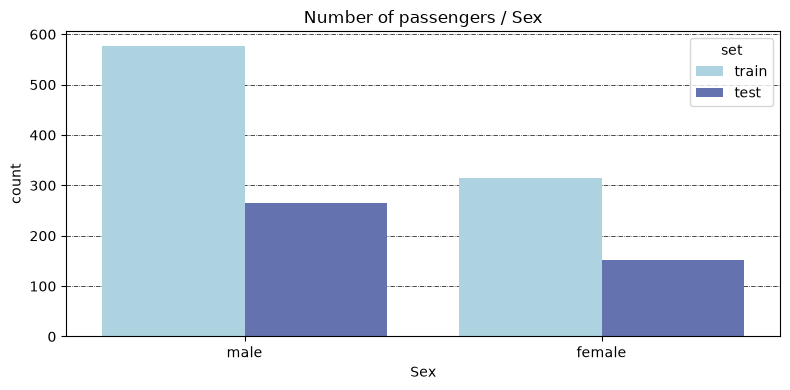

In [6]:
plot_counts(all_df, "Sex", "set", DATASET_PALETTE, FIGSIZE)

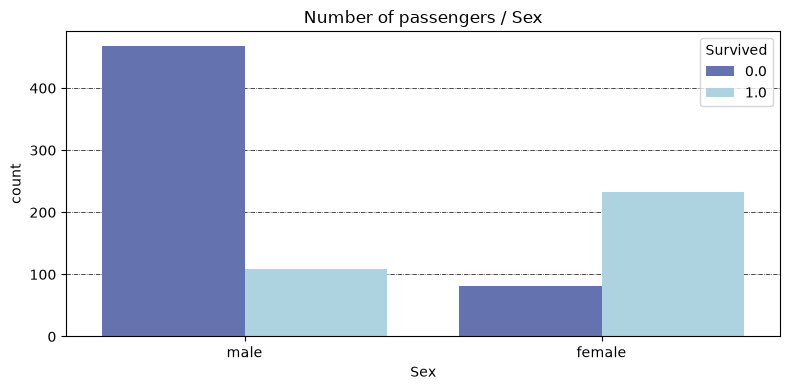

In [7]:
plot_counts(all_df, "Sex", TARGET, SURVIVAL_PALETTE, FIGSIZE)

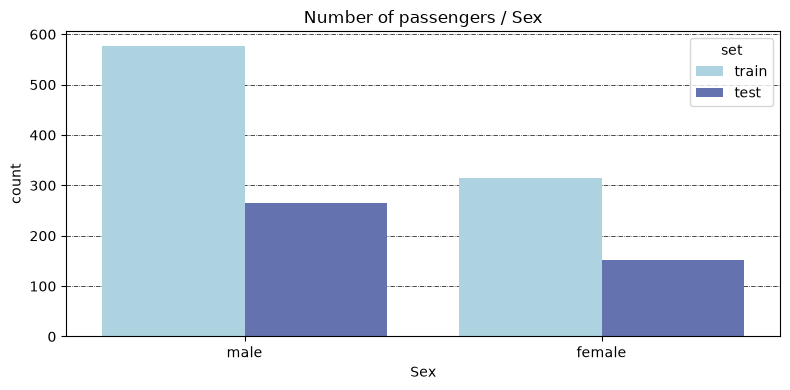

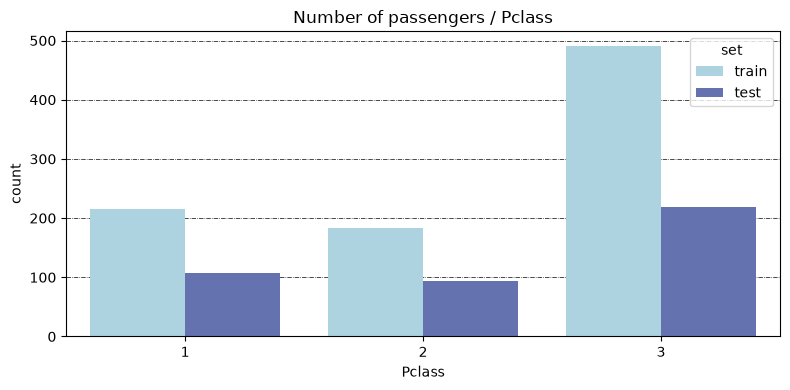

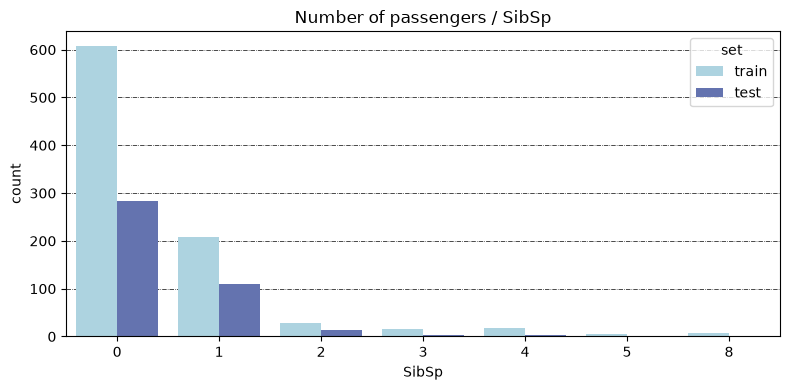

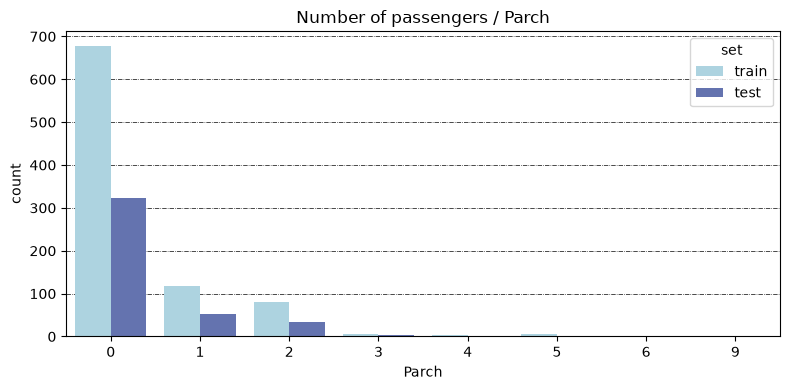

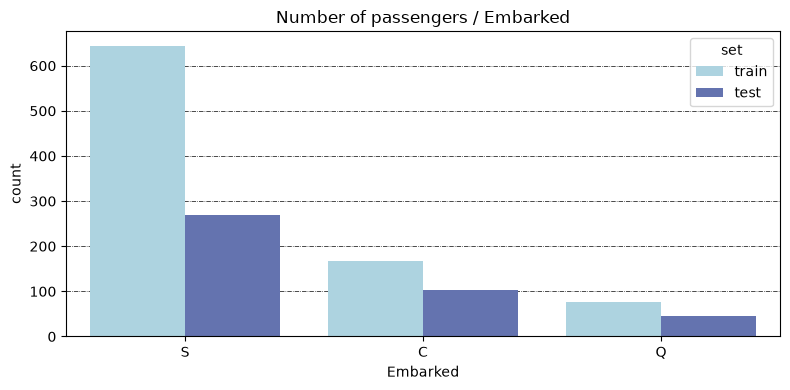

In [8]:
for column in CATEGORICAL_FEATURES:
    plot_counts(all_df, column, "set", DATASET_PALETTE, FIGSIZE)

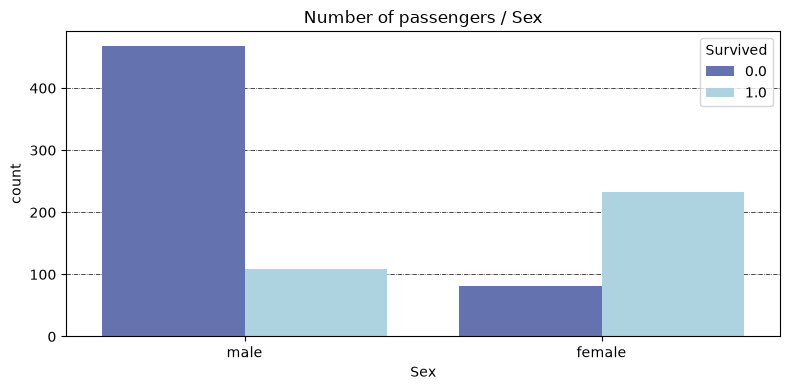

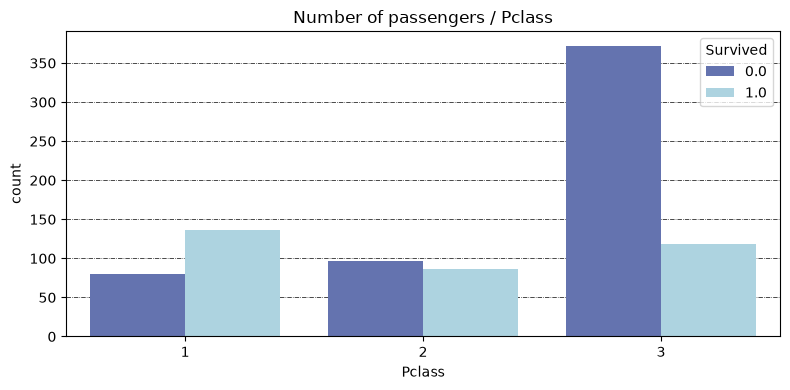

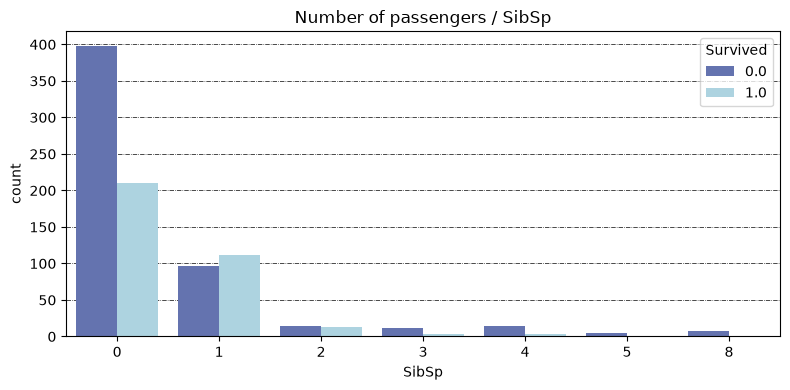

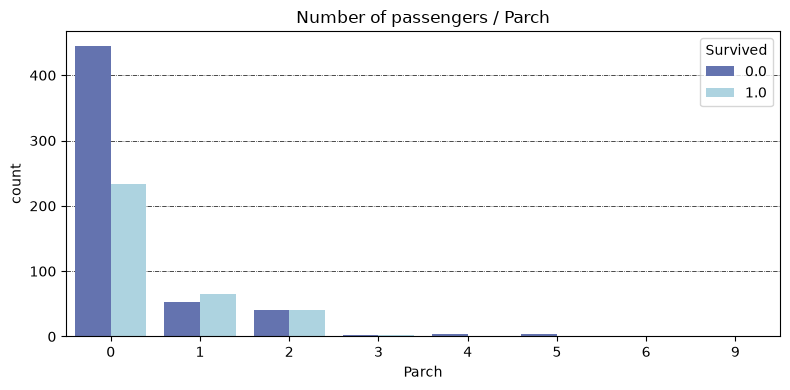

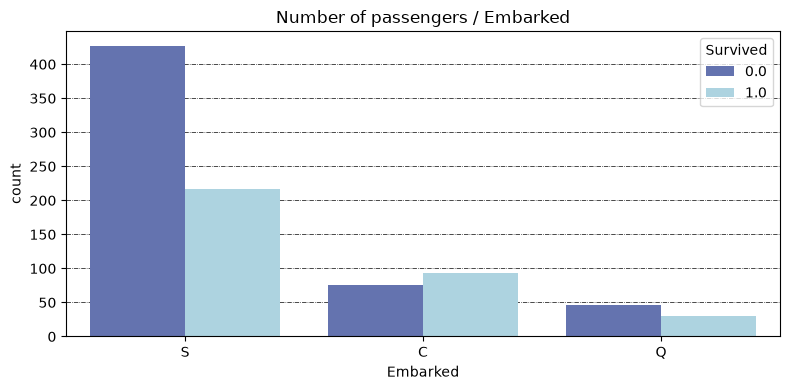

In [9]:
for column in CATEGORICAL_FEATURES:
    plot_counts(all_df, column, TARGET, SURVIVAL_PALETTE, FIGSIZE)

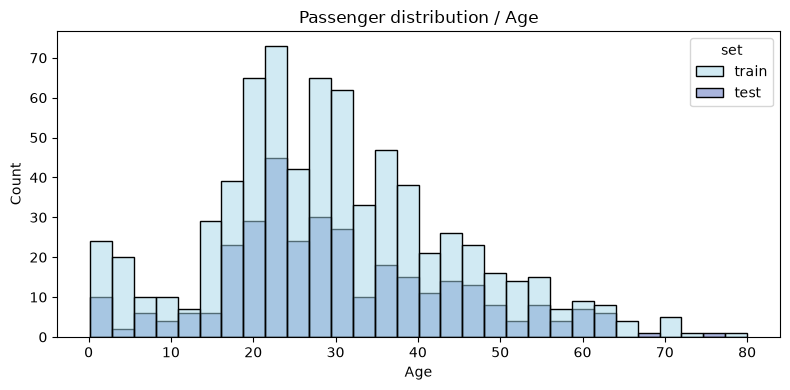

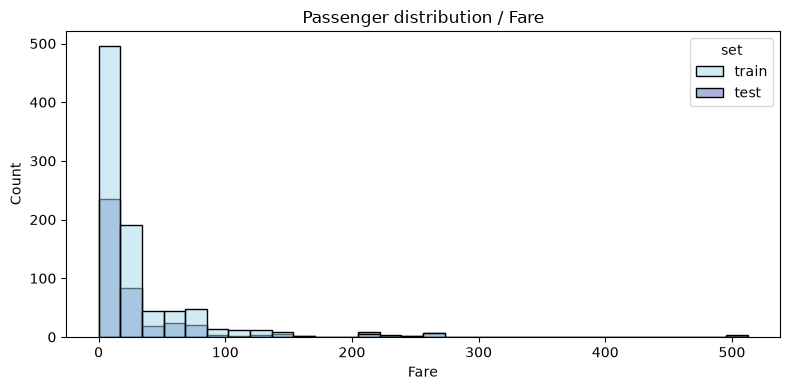

In [10]:
for column in CONTINUOUS_FEATURES:
    plot_distributions(all_df, column, "set", DATASET_PALETTE, FIGSIZE, HIST_BINS)

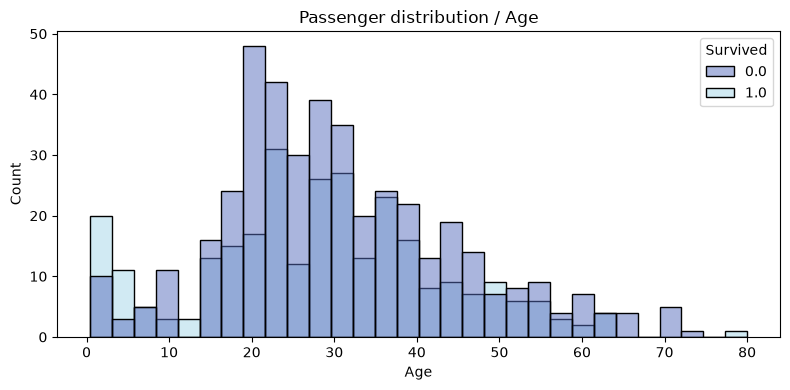

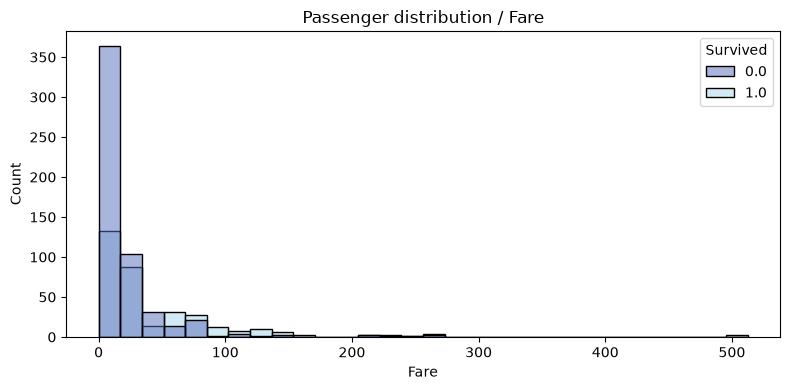

In [11]:
for column in CONTINUOUS_FEATURES:
    plot_distributions(all_df, column, TARGET, SURVIVAL_PALETTE, FIGSIZE, HIST_BINS)

## Family size


Based on SibSp (sibilings or spouse) and Parch (parents or children), we set the Family Size field.

In [12]:
all_df = add_family_size(all_df)

In [13]:
train_df = add_family_size(train_df)

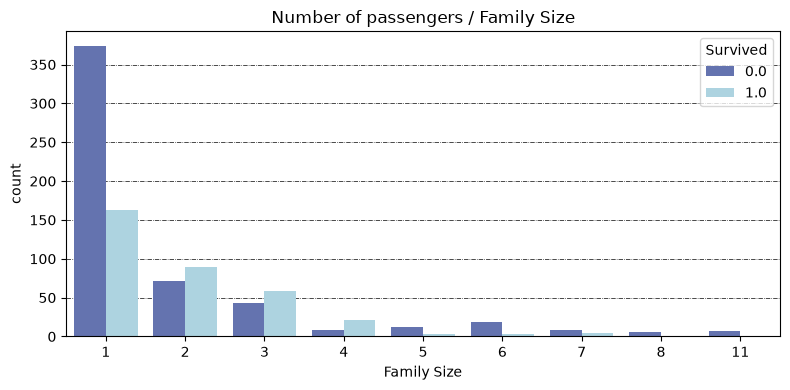

In [14]:
plot_counts(all_df, "Family Size", TARGET, SURVIVAL_PALETTE, FIGSIZE)

## Age interval

In [15]:
all_df = add_age_interval(all_df, AGE_BOUNDARIES)

In [16]:
train_df = add_age_interval(train_df, AGE_BOUNDARIES)

In [17]:
all_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,set,Family Size,Age Interval
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,train,2,1.0
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,train,2,2.0
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,train,1,1.0
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,train,2,2.0
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,train,1,2.0


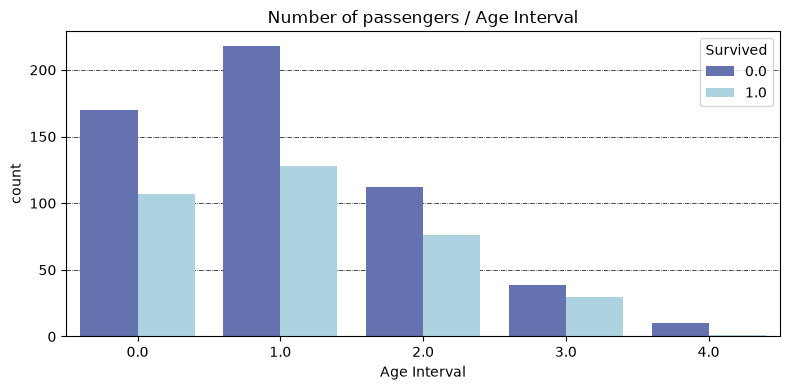

In [18]:
plot_counts(all_df, "Age Interval", TARGET, SURVIVAL_PALETTE, FIGSIZE)

## Fare interval

In [19]:
all_df = add_fare_interval(all_df, FARE_BOUNDARIES)

In [20]:
train_df = add_fare_interval(train_df, FARE_BOUNDARIES)

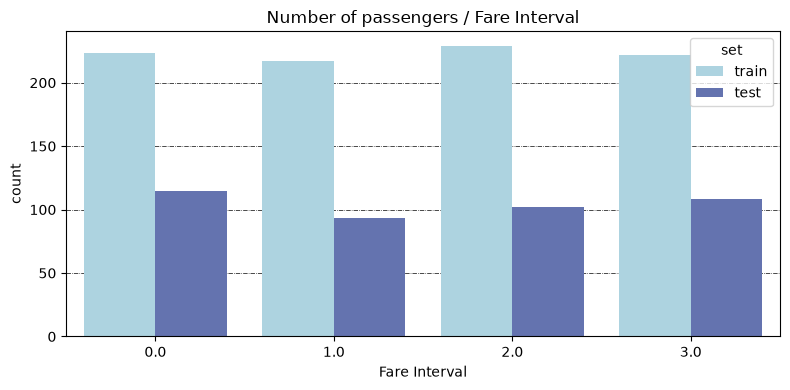

In [21]:
plot_counts(all_df, "Fare Interval", "set", DATASET_PALETTE, FIGSIZE)

Let's create a composed feature: Pclass + Sex.

In [22]:
train_df = add_sex_pclass(train_df)

In [23]:
all_df = add_sex_pclass(all_df)

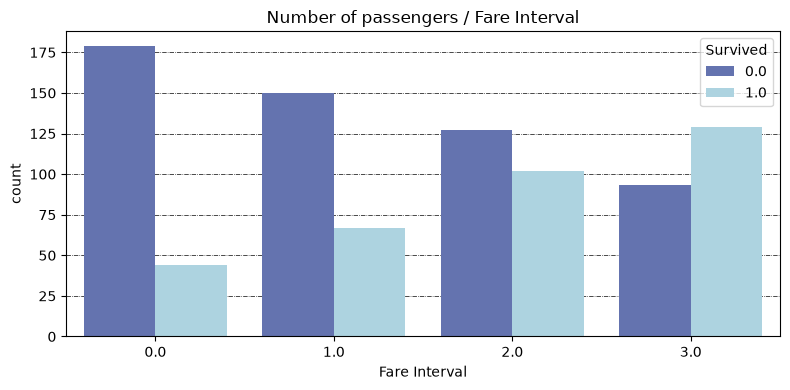

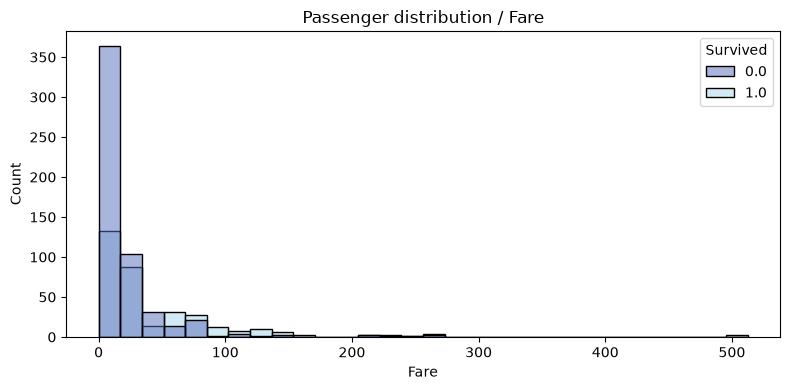

In [24]:
plot_counts(all_df, "Fare Interval", TARGET, SURVIVAL_PALETTE, FIGSIZE)
plot_distributions(all_df, "Fare", TARGET, SURVIVAL_PALETTE, FIGSIZE, HIST_BINS)

## Process names


When we process names, we would like to extract the following information:

- Family name - this is the first word (or few first words, if a family name with multiple names), followed by a comma  
- Title - this follows just after the comma   
- Given name - this is the word or group of words following family name  
- Maiden name - for ladies, is given between parantheses  

We start with creating a function that parses the Name string and extract (if possible) these 4 elements


In [25]:
from titanic.features import parse_names

In [26]:
all_df = parse_names_execution(all_df, NAME_COLUMNS)

In [27]:
train_df = parse_names_execution(train_df, NAME_COLUMNS)

## Multivariate analysis


Let's look now to the interaction of multiple features.

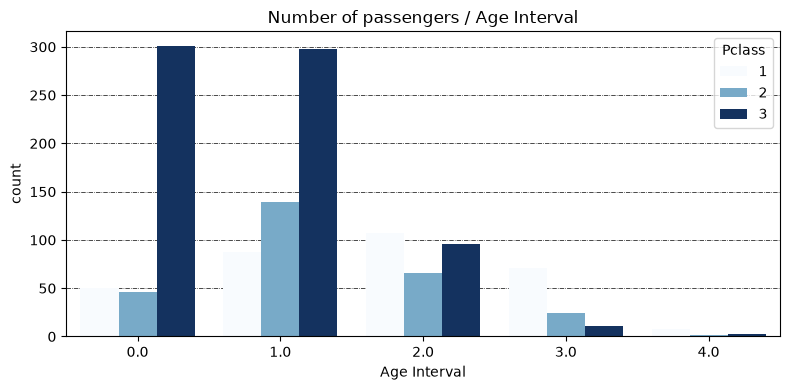

In [28]:
plot_counts(all_df, "Age Interval", "Pclass", GROUP_PALETTE, FIGSIZE)

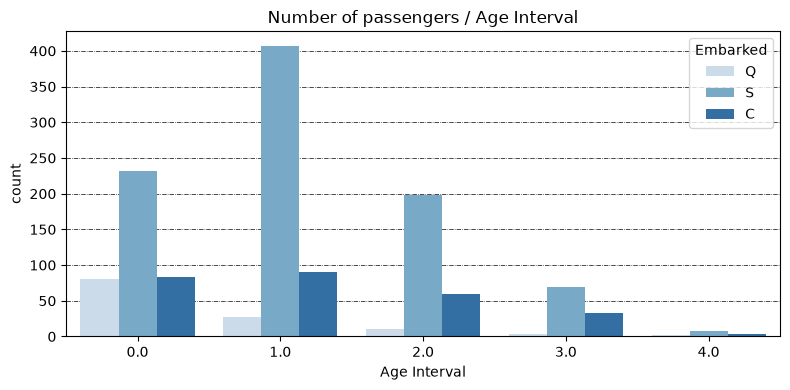

In [29]:
plot_counts(all_df, "Age Interval", "Embarked", GROUP_PALETTE, FIGSIZE)

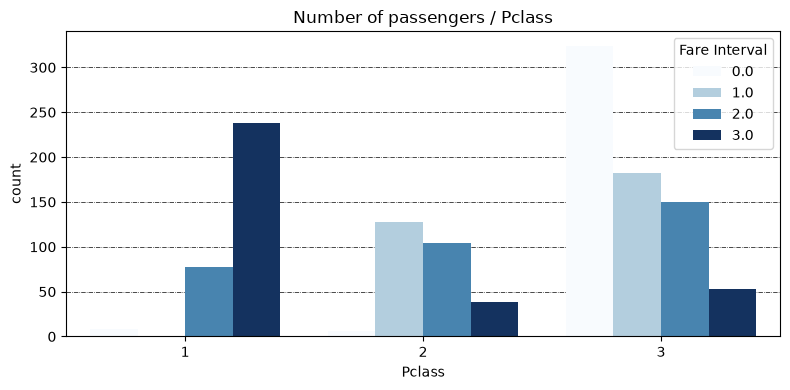

In [30]:
plot_counts(all_df, "Pclass", "Fare Interval", GROUP_PALETTE, FIGSIZE)

### Few more engineered data 


Let's create two more engineered features:  
* Family size interval: Single, Small, Large  
* Aggregated titles: Mr, Mrs, Master, Miss, and Rare  

In [31]:
all_df = add_family_type(all_df)

In [32]:
train_df = add_family_type(train_df)

In [33]:
all_df = add_aggregated_titles(all_df)

In [34]:
train_df = add_aggregated_titles(train_df)

In [35]:
summarise_survival(train_df)

,Titles,Sex,Survived
0,Master.,male,0.575000
1,Miss.,female,0.702703
2,Mr.,male,0.156673
3,Mrs.,female,0.793651
4,Rare,female,1.000000
5,Rare,male,0.250000


# Baseline model

## Feature engineering: Map categorical value to numerical values

In [36]:
train_df = unify_sex(train_df, SEX_MAPPING)
test_df = unify_sex(test_df, SEX_MAPPING)

Create train-validation split.

In [37]:
train, valid = train_test_split(
    train_df, test_size=VALID_SIZE, random_state=RANDOM_STATE, shuffle=SHUFFLE
)

Define predictor features and target feature.

In [38]:
predictors = PREDICTORS
target = TARGET

Define the training and validation data and labels.

In [39]:
train_X, train_Y = features_and_target(train, predictors, target)
valid_X, valid_Y = features_and_target(valid, predictors, target)

Fit the classifier and predict the training and validation data.

In [40]:
clf, preds_tr, preds = train_and_predict(
    train_X, train_Y, valid_X, **MODEL_PARAMETERS
)

Inspect the fitted classifier.

In [41]:
clf

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

Predict the train data (to check the training classification error).

In [42]:
preds_tr

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0,

Predict the validation data.

In [43]:
preds

array([0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 0])

# Evaluation

## Classification report for training data.

In [44]:
print(metrics.classification_report(train_Y, preds_tr, target_names=CLASS_NAMES))

              precision    recall  f1-score   support

Not Survived       0.75      0.99      0.86       444
    Survived       0.96      0.47      0.63       268

    accuracy                           0.79       712
   macro avg       0.86      0.73      0.74       712
weighted avg       0.83      0.79      0.77       712



Classification report for validation data.

In [45]:
print(metrics.classification_report(valid_Y, preds, target_names=CLASS_NAMES))

              precision    recall  f1-score   support

Not Survived       0.73      0.96      0.83       105
    Survived       0.90      0.49      0.63        74

    accuracy                           0.77       179
   macro avg       0.81      0.72      0.73       179
weighted avg       0.80      0.77      0.75       179

